# Medical Insurance Charges — Regression

The classic `insurance.csv` from Brett Lantz's *Machine Learning with R* — 1,338 rows, target is `charges` (the actual billed amount), features are age, sex, BMI, children, smoker flag, region.

Smoker status alone explains a huge chunk of variance — that's the well-known result on this dataset. The interesting modeling question is how much extra signal you get from the other variables once smoker is in the model.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

np.random.seed(0)
df = pd.read_csv("../../data/medical_insurance/insurance.csv")
print(df.shape)
df.describe(include="all").T


(1338, 7)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1338.0,NaN,NaN,NaN,41.219731,13.586021,18.0,30.0,41.0,53.0,64.0
sex,1338,2,male,674,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1338.0,NaN,NaN,NaN,30.390403,6.070425,15.0,26.277,30.358,34.52025,50.283
children,1338.0,NaN,NaN,NaN,1.130045,1.270272,0.0,0.0,1.0,2.0,5.0
smoker,1338,2,no,1078,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,northeast,366,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,1338.0,NaN,NaN,NaN,16877.687219,7571.353913,3664.54345,11475.858685,15076.56757,19472.33311,46252.53408


## Quick EDA

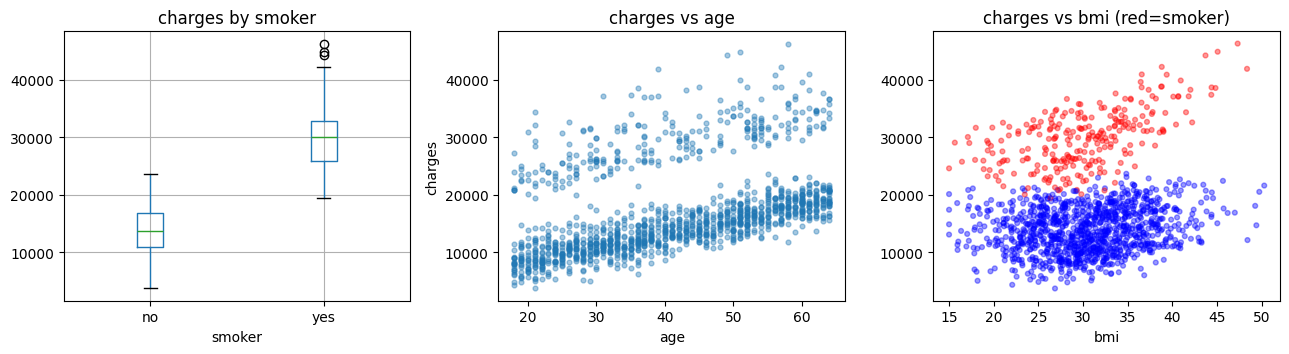

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
df.boxplot(column="charges", by="smoker", ax=axes[0]); axes[0].set_title("charges by smoker")
axes[1].scatter(df["age"], df["charges"], alpha=0.4, s=12); axes[1].set_xlabel("age"); axes[1].set_ylabel("charges")
axes[1].set_title("charges vs age")
axes[2].scatter(df["bmi"], df["charges"], c=(df.smoker=="yes").map({True:"red", False:"blue"}), alpha=0.4, s=12)
axes[2].set_xlabel("bmi"); axes[2].set_title("charges vs bmi (red=smoker)")
plt.suptitle(""); plt.tight_layout(); plt.show()
# note to self: smokers form a clearly separated band, especially as BMI goes up.


## Models

In [3]:
X = pd.get_dummies(df.drop(columns=["charges"]), drop_first=True).astype(float)
feature_names = X.columns.tolist()
X = X.values
y = df["charges"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

models = {
    "Linear":           (LinearRegression(),                                            X_train_s, X_test_s),
    "Ridge":            (Ridge(alpha=1.0),                                              X_train_s, X_test_s),
    "RandomForest":     (RandomForestRegressor(n_estimators=400, random_state=0, n_jobs=-1), X_train, X_test),
    "GradientBoosting": (GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=0),
                         X_train, X_test),
}

for name, (m, Xtr, Xte) in models.items():
    m.fit(Xtr, y_train)
    pred = m.predict(Xte)
    print(f"{name:18s}  R^2={r2_score(y_test, pred):.3f}  MAE=${mean_absolute_error(y_test, pred):,.0f}")


Linear              R^2=0.934  MAE=$1,383
Ridge               R^2=0.934  MAE=$1,382


RandomForest        R^2=0.949  MAE=$1,210


GradientBoosting    R^2=0.951  MAE=$1,216


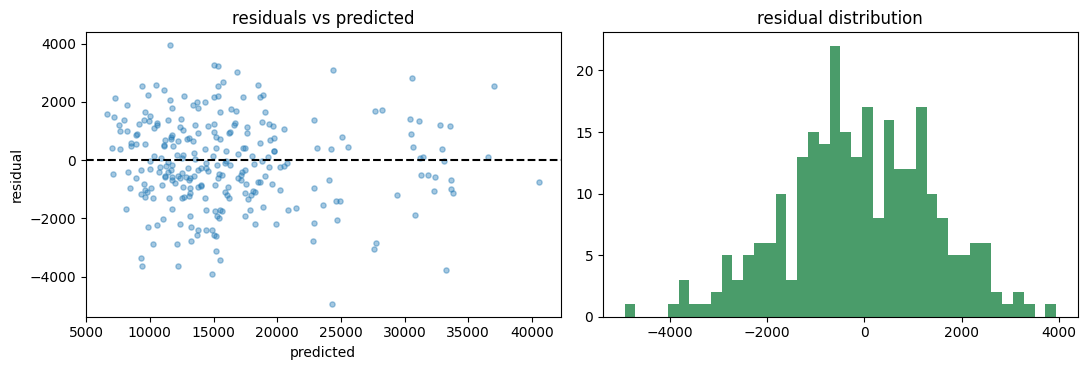

In [4]:
# residuals on the best (usually GB) model
gb = models["GradientBoosting"][0]
pred = gb.predict(X_test)
resid = y_test - pred

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(pred, resid, alpha=0.4, s=14); axes[0].axhline(0, color="k", ls="--")
axes[0].set_xlabel("predicted"); axes[0].set_ylabel("residual"); axes[0].set_title("residuals vs predicted")
axes[1].hist(resid, bins=40, color="#4a9c6a"); axes[1].set_title("residual distribution")
plt.tight_layout(); plt.show()


## Takeaways

The headline story on this dataset has been consistent across every analysis I've seen:

1. Smoker is by far the single strongest predictor. A linear regression with just `smoker` gets you most of the way.
2. BMI matters mostly *through* smoker — high-BMI smokers blow up the charges in a way that's not linear.
3. Age contributes a roughly linear ramp; sex and region barely move the needle.

The gradient boosting model usually edges out linear regression on this dataset because of the smoker × BMI interaction. A linear model can capture that too if you explicitly add an interaction term, but the tree models pick it up for free.

Residuals are not super clean — there's heteroscedasticity, with high predictions having wider residual spread. A log-transform on the target (`log1p(charges)`) tends to tighten things up if you care about MAPE rather than MAE. I didn't bother for this notebook because the comparison was already informative.
